# Trực quan hóa 5 cách mã hóa AMO

Nguồn dữ liệu: `results/data/amo_120s.csv`; notebook lọc 33 đồ thị `hb_33` trong CSV chung 113 đồ thị (mỗi đồ thị chạy 5 AMO; Pairwise + Incremental, giới hạn 120 giây/lượt).

Chạy notebook từ trên xuống dưới bằng kernel Python của `.venv`. Hai hình được lưu thêm vào `report/figures/` để đưa vào báo cáo. Sử dụng [`cnsplots`](https://cnsplots.farid.one/latest/) cho cả grouped bars và heatmap.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import cnsplots as cns

AMO_ORDER = ["Binomial", "Binary", "Commander", "Product", "Sequential"]
root = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "results/data/amo_120s.csv").is_file()), None)
if root is None:
    raise FileNotFoundError("Không tìm thấy results/data/amo_120s.csv; hãy mở notebook trong dự án BMP")
csv_path = root / "results/data/amo_120s.csv"
figure_dir = root / "report/figures"
figure_dir.mkdir(parents=True, exist_ok=True)
print("Đang đọc:", csv_path)


Đang đọc: D:\EXP\year-3-semester-1\Contemporary-issues-in-computer-science\Bandwidth-Minimization-Problem\results\data\amo_120s.csv


## Đọc và kiểm tra dữ liệu

Một instance phải có đúng một dòng cho mỗi AMO. Bandwidth càng **nhỏ** càng tốt. `OPTIMAL` nghĩa là solver đã chứng minh không thể có bandwidth nhỏ hơn; `FEASIBLE` chỉ có nghiệm khả thi hiện tốt nhất khi hết thời gian.


In [2]:
amo = pd.read_csv(csv_path)
hb33_names = {p.name.removesuffix(".mtx.rnd") for p in (root / "data/hb_33").glob("*.mtx.rnd")}
amo = amo[amo["instance"].isin(hb33_names)].copy()
required = {"instance", "cardinality", "status", "bandwidth"}
if not required.issubset(amo.columns):
    raise ValueError(f"CSV thiếu cột: {required - set(amo.columns)}")
if len(amo) != 33 * 5 or amo["instance"].nunique() != 33:
    raise ValueError("Cần đúng 165 dòng cho 33 đồ thị và 5 AMO")
if set(amo["cardinality"]) != set(AMO_ORDER):
    raise ValueError("Danh sách AMO không khớp năm cấu hình cần so sánh")
if amo.duplicated(["instance", "cardinality"]).any():
    raise ValueError("Có cặp instance/AMO bị lặp")
if not amo.groupby("instance")["cardinality"].nunique().eq(5).all():
    raise ValueError("Có đồ thị thiếu một cách mã hóa AMO")
if not amo["status"].isin(["OPTIMAL", "FEASIBLE", "TIMEOUT", "ERROR"]).all():
    raise ValueError("Trạng thái solver không hợp lệ")
amo["bandwidth"] = pd.to_numeric(amo["bandwidth"], errors="raise")
if amo["bandwidth"].isna().any():
    raise ValueError("Có dòng chưa tìm được bandwidth; cần quy ước riêng trước khi vẽ")
wide = amo.pivot(index="instance", columns="cardinality", values="bandwidth")[AMO_ORDER]
best_by_instance = wide.min(axis=1)
print(f"Đã kiểm tra: {len(amo)} dòng, {len(wide)} đồ thị, {len(AMO_ORDER)} AMO")


Đã kiểm tra: 165 dòng, 33 đồ thị, 5 AMO


## Hình 1 — Số lần đạt nghiệm tốt nhất và chứng minh OPTIMAL

Với từng đồ thị, lấy bandwidth nhỏ nhất trong **5 AMO của CSV này**. Mỗi AMO đạt đúng giá trị ấy được tính một lần; nếu hòa, tất cả AMO hòa đều được tính. Cột `OPTIMAL` đếm trực tiếp trạng thái trong CSV. Vì có hòa, tổng các cột màu xanh có thể lớn hơn 33.


,Đạt bandwidth tốt nhất,Chứng minh OPTIMAL
cardinality,,
Binomial,8,3
Binary,14,4
Commander,13,4
Product,17,5
Sequential,15,7


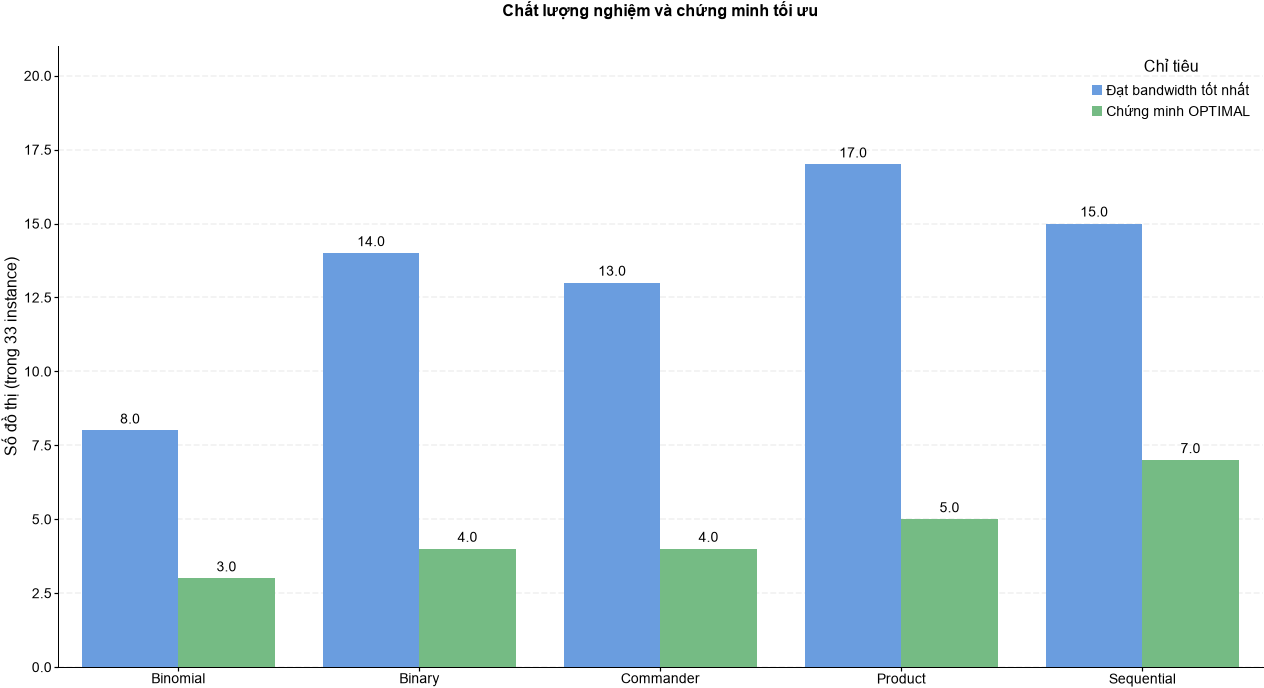

In [3]:
best_count = wide.eq(best_by_instance, axis=0).sum().reindex(AMO_ORDER).astype(int)
optimal_count = (amo.assign(is_optimal=amo["status"].eq("OPTIMAL"))
                 .groupby("cardinality")["is_optimal"].sum()
                 .reindex(AMO_ORDER).astype(int))
summary = pd.DataFrame({"Đạt bandwidth tốt nhất": best_count,
                        "Chứng minh OPTIMAL": optimal_count})
display(summary)

bars = (summary.rename_axis("AMO").reset_index()
        .melt(id_vars="AMO", var_name="Chỉ tiêu", value_name="Số đồ thị"))
fig = cns.figure(9, 5, unit="in")
ax = cns.barplot(data=bars, x="AMO", y="Số đồ thị", hue="Chỉ tiêu",
                 order=AMO_ORDER, hue_order=list(summary.columns),
                 palette={"Đạt bandwidth tốt nhất": "#579BF2",
                          "Chứng minh OPTIMAL": "#69C77D"},
                 errorbar=None, dodge=True, add_tip=True)
ax.set_title("Chất lượng nghiệm và chứng minh tối ưu", pad=15)
ax.set_xlabel("")
ax.set_ylabel("Số đồ thị (trong 33 instance)")
ax.set_ylim(0, max(summary.max()) + 4)
ax.yaxis.grid(True, alpha=0.18, linestyle="--")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(figure_dir / "amo_grouped_bars.png", dpi=220, bbox_inches="tight")
plt.show()


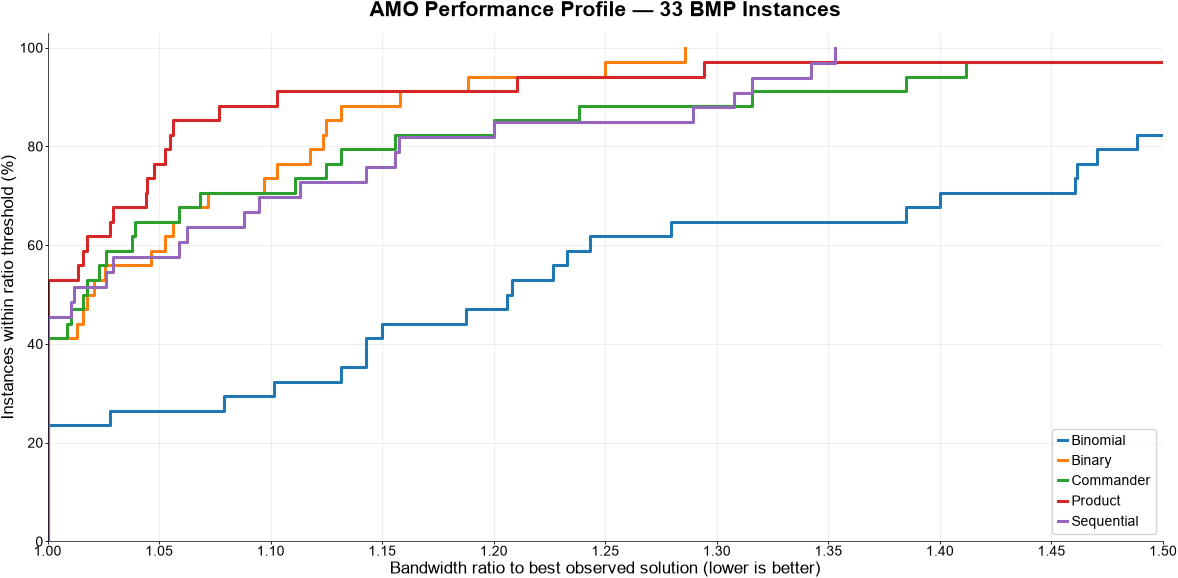

In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Xác định thư mục gốc dự án
# Hoạt động khi chạy notebook từ thư mục gốc hoặc notebooks/
cwd = Path.cwd()

if (cwd / "results" / "data" / "amo_120s.csv").exists():
    ROOT = cwd
elif (cwd.parent / "results" / "data" / "amo_120s.csv").exists():
    ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Không tìm thấy results/data/amo_120s.csv"
    )

# 2. Đọc dữ liệu
df = pd.read_csv(ROOT / "results" / "data" / "amo_120s.csv")

order = [
    "Binomial",
    "Binary",
    "Commander",
    "Product",
    "Sequential",
]

# 3. Tính bandwidth ratio
best = df.groupby("instance")["bandwidth"].min()
df["ratio"] = df["bandwidth"] / df["instance"].map(best)

# 4. Giữ nguyên màu của biểu đồ gốc
colors = {
    "Binomial": "tab:blue",
    "Binary": "tab:orange",
    "Commander": "tab:green",
    "Product": "tab:red",
    "Sequential": "tab:purple",
}

# 5. Vẽ một biểu đồ duy nhất
fig, ax = plt.subplots(figsize=(12, 6))

for method in order:
    ratios = np.sort(
        df.loc[
            df["cardinality"] == method,
            "ratio"
        ].to_numpy()
    )

    n = len(ratios)

    x = np.r_[1.0, ratios]
    y = np.r_[0.0, np.arange(1, n + 1) / n * 100]

    ax.step(
        x,
        y,
        where="post",
        linewidth=2.2,
        color=colors[method],
        label=method,
    )

# 6. Giới hạn X từ 1.0 đến 1.5
ax.set_xlim(1.0, 1.5)
ax.set_ylim(0, 103)

ax.set_xticks(np.arange(1.0, 1.51, 0.05))

ax.set_xlabel(
    "Bandwidth ratio to best observed solution (lower is better)",
    fontsize=12,
)

ax.set_ylabel(
    "Instances within ratio threshold (%)",
    fontsize=12,
)

ax.set_title(
    "AMO Performance Profile — 33 BMP Instances",
    fontsize=15,
    pad=12,
)

ax.grid(True, alpha=0.2)
ax.tick_params(labelsize=10)

# Legend không che dữ liệu
ax.legend(
    loc="lower right",
    fontsize=10,
    frameon=True,
)

plt.tight_layout()

# 7. Xuất hình
output_dir = ROOT / "results" / "figures"
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "amo_performance_profile.pdf",
    bbox_inches="tight",
)

fig.savefig(
    output_dir / "amo_performance_profile.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()